## 1. Imports

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from pathlib import Path
import matplotlib.pyplot as plt
import sys
sys.path.append(str(Path("src").resolve()))
from nlp import apply_nlp

## 2. Preprocessing

In [3]:
data_path = Path("../data/processed")

csv_files = list(data_path.glob("*.csv"))


def read_datasets(datasets):
    dataframe = {}
    for dataset in datasets:
        filename = dataset.name
        dataframe[filename] = pd.read_csv(dataset)
    return dataframe

def convert_to_datetime(dataset, columns):
    for column in columns:
        dataset[column] = pd.to_datetime(dataset[column])
    return dataset

orders_dataset_columns_to_datetime = [
    "order_purchase_timestamp", 
    "order_approved_at", 
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date" 
    ]

order_items_dataset_columns_to_datetime = [
    "shipping_limit_date" 
    ]

order_reviews_dataset_columns_to_datetime = [
    "review_creation_date",
    "review_answer_timestamp" 
    ]

datasets = read_datasets(csv_files)

customers_dataset = datasets["olist_customers_dataset.csv"]
geolocation_dataset = datasets["olist_geolocation_dataset.csv"]
order_payments_dataset = datasets["olist_order_payments_dataset.csv"]
products_dataset = datasets["olist_products_dataset.csv"]
sellers_dataset = datasets["olist_sellers_dataset.csv"]
category_translation_dataset = datasets["product_category_name_translation.csv"]

orders_dataset = convert_to_datetime(dataset=datasets["olist_orders_dataset.csv"], columns=orders_dataset_columns_to_datetime)
orders_items_dataset = convert_to_datetime(dataset=datasets["olist_order_items_dataset.csv"], columns=order_items_dataset_columns_to_datetime)
reviews_dataset = convert_to_datetime(dataset=datasets["olist_order_reviews_dataset.csv"], columns=order_reviews_dataset_columns_to_datetime)

display(Markdown("The attributes datatypes check for the **`olist_orders_dataset`**"))
display(orders_dataset.dtypes)
print("-"*100)
display(Markdown("The attributes datatypes check for the **`olist_order_items_dataset`**"))
display(orders_items_dataset.dtypes)
print("-"*100)
display(Markdown("The attributes datatypes check for the **`olist_order_reviews_dataset`**"))
display(reviews_dataset.dtypes)

The attributes datatypes check for the **`olist_orders_dataset`**

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

----------------------------------------------------------------------------------------------------


The attributes datatypes check for the **`olist_order_items_dataset`**

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

----------------------------------------------------------------------------------------------------


The attributes datatypes check for the **`olist_order_reviews_dataset`**

review_id                             str
order_id                              str
review_score                        int64
review_comment_title                  str
review_comment_message                str
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object

# 3. EDA Analysis

## 3.2 Customers Analysis

### 3.2.1 How many customers?

In [5]:
unique_customers = customers_dataset["customer_unique_id"].nunique()
all_customers = customers_dataset["customer_id"].count()
display(Markdown(f"Total number of unique customers: **{unique_customers}**"))
display(Markdown(f"Total number of customers (one customer_id = one order): **{all_customers}**"))

Total number of unique customers: **96096**

Total number of customers (one customer_id = one order): **99441**

In [6]:
number_of_repeated_customers = customers_dataset["customer_unique_id"].value_counts().gt(1).sum()
display(Markdown(f"Number of repeated customers(customers who made more than one order): **{number_of_repeated_customers}**"))

Number of repeated customers(customers who made more than one order): **2997**

Insight:
- Total number of unique customers, meaning one custoner represents one unique person, is **96096**
- Out of these customers **2997** customers made order more than once
- The marketplace demonstrates low customer retention, with approximately **3%** of customers making more than one purchase.

### 3.2.2 Where are customers located? Which states have the most customers?

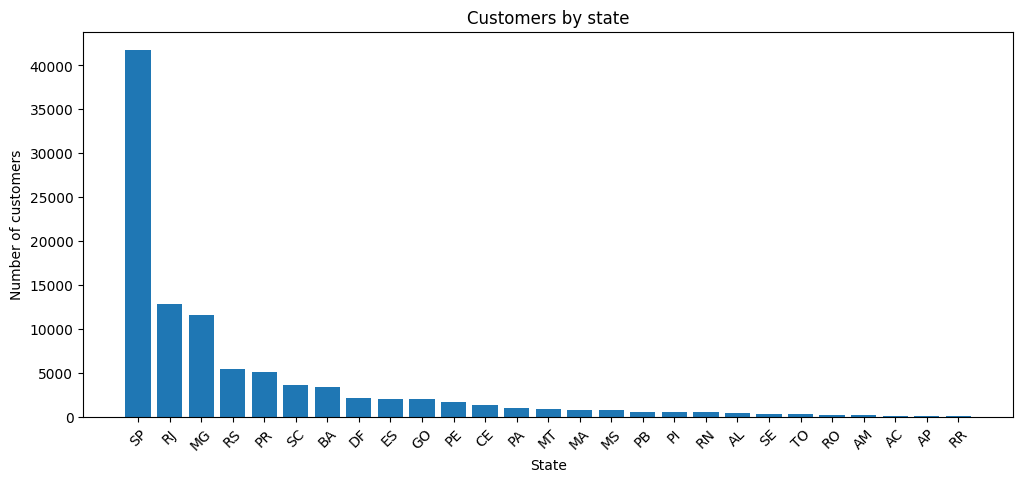

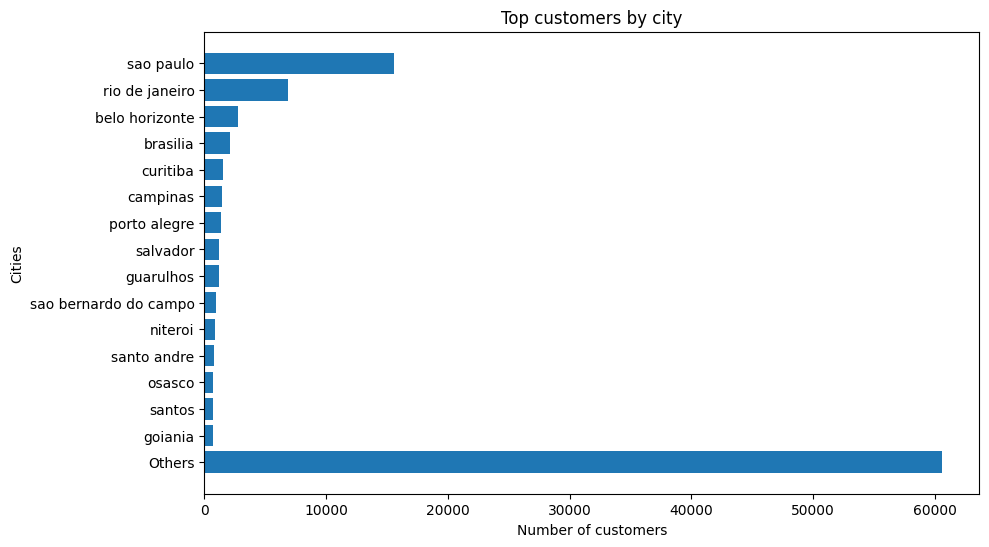

In [7]:
customers_by_state = customers_dataset["customer_state"].value_counts()

customers_by_city = customers_dataset["customer_city"].value_counts()
top_15_customers_by_city = customers_by_city.iloc[:15]


others_customers_by_city = pd.Series({
    "Others": customers_by_city.iloc[15:].sum()
})


pd_customers_by_city = pd.concat([
    top_15_customers_by_city,
    others_customers_by_city
])


plt.figure(figsize=(12, 5))
plt.bar(
    customers_by_state.index,
    customers_by_state.values
)

plt.title("Customers by state")
plt.xlabel("State")
plt.ylabel("Number of customers")

plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))
plt.barh(pd_customers_by_city.index, pd_customers_by_city.values)
plt.title("Top customers by city")
plt.xlabel("Number of customers")
plt.ylabel("Cities")

plt.gca().invert_yaxis()

plt.show()

Insight:
- Large customer base: The dataset contains 99,441 customers in total.
- Customers are highly concentrated in a few states: São Paulo (SP) has 41,746 customers, making it by far the largest customer base. Rio de Janeiro (RJ) follows with 12,852, and Minas Gerais (MG) with 11,635.
- São Paulo is particularly dominant: SP alone accounts for roughly 42% of all customers, showing a strong geographic concentration in Brazil's Southeast region.
- The Southeast dominates the customer base: SP, RJ, and MG together account for approximately 66% of all customers, indicating that the customer base is heavily concentrated in these states.
- Customer distribution becomes more fragmented at the city level: The 15 largest cities account for 38,839 customers, while 60,602 customers come from other cities.
- São Paulo city is the largest individual market: With 15,540 customers, São Paulo has more than twice as many customers as Rio de Janeiro (6,882).
- Rio de Janeiro and Belo Horizonte are the next largest cities: They have 6,882 and 2,773 customers respectively, followed by Brasília (2,131) and Curitiba (1,521).
- Overall, the customer base is geographically concentrated at the state level but more dispersed at the city level: A few states account for a large share of customers, while customers are spread across a much larger number of cities.

## 3.3 Sellers Analysis

### 3.3.1 How many sellers?

In [9]:
number_of_sellers = sellers_dataset["seller_id"].nunique()
display(Markdown(f"Total number of unique sellers: **{number_of_sellers}**"))

Total number of unique sellers: **3095**

### 3.3.2 Where are sellers located?

In [130]:
#Where are sellers located?
sellers_states = sellers_dataset["seller_state"].value_counts().head(10)
sellers_cities = sellers_dataset["seller_city"].value_counts().head(10)

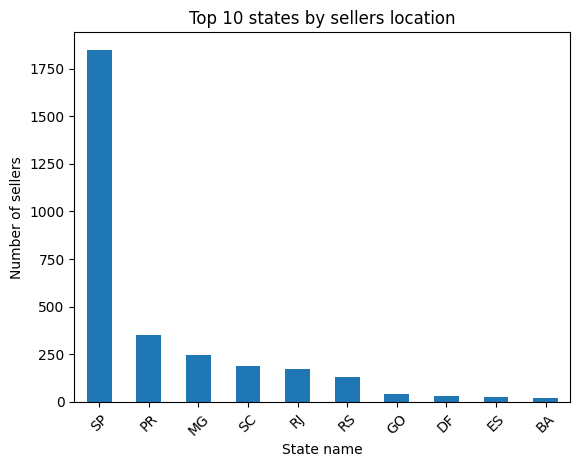

In [128]:
sellers_states.plot.bar(
    title="Top 10 states by sellers location",
    xlabel="State name",
    ylabel="Number of sellers"
)

plt.xticks(rotation=45)
plt.show()

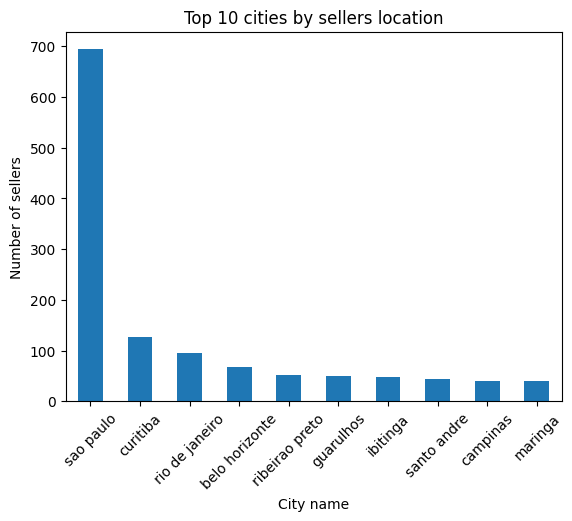

In [129]:
sellers_cities.plot.bar(
    title="Top 10 cities by sellers location",
    xlabel="City name",
    ylabel="Number of sellers"
)

plt.xticks(rotation=45)
plt.show()

Insight:
- Seller concentration is very high in São Paulo: SP has 1,849 sellers, far more than any other state. Paraná is a distant second with 349 sellers.
- The seller base is heavily concentrated in Brazil's Southeast and South: São Paulo, Paraná, Minas Gerais, Santa Catarina, Rio de Janeiro, and Rio Grande do Sul account for the vast majority of the sellers shown.
- São Paulo city is the largest seller hub: With 694 sellers, São Paulo has more than five times the sellers of Curitiba (127) and more than seven times those of Rio de Janeiro (96).
- Seller activity is concentrated in a relatively small number of cities: Among the cities shown, São Paulo is clearly dominant, followed by Curitiba, Rio de Janeiro, and Belo Horizonte.
- There is a substantial geographic imbalance between sellers and customers: Your earlier customer analysis also showed São Paulo as the dominant customer state. This suggests that São Paulo is important on both the supply and demand sides of the marketplace.
- Overall, the seller network appears highly centralized geographically, with São Paulo serving as the strongest seller hub and the South/Southeast regions accounting for most of the seller presence.

### 3.3.3 Orders by Sellers

In [131]:
#Determine number of orders by sellers?
unique_orders = orders_items_dataset.drop_duplicates(subset=["order_id", "seller_id"])
top_sellers_by_number_of_orders = unique_orders["seller_id"].value_counts()
number_orders_by_top_15_sellers = top_sellers_by_number_of_orders.head(15).sum()
display(Markdown(f"Percentage of orders by top 15 of sellers: {round((number_orders_by_top_15_sellers / unique_orders["order_id"].count()) * 100, 2)}%"))
orders_by_sellers = orders_items_dataset.groupby("order_id")["seller_id"].nunique().sort_values(ascending=False)
orders_by_sellers.describe()

Percentage of orders by top 15 of sellers: 18.19%

count    98666.000000
mean         1.013622
std          0.122297
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          5.000000
Name: seller_id, dtype: float64

Insight:
- The top 15 sellers contribute only 18.19% of total orders, indicating a highly distributed seller network with limited dependence on the largest sellers.
- Orders are typically fulfilled by a single seller, with an average of 1.01 sellers per order and a maximum of 5 sellers, showing that multi-seller purchases are uncommon.
- This suggests the marketplace operates with a large number of independent sellers while maintaining relatively simple order structures.

## 3.4 Products Analysis

### 3.4.1 How many products?

In [14]:
number_of_unique_products = products_dataset["product_id"].nunique()
display(Markdown(f"Total number of unique products: **{number_of_unique_products}**"))

Total number of unique products: **32951**

### 3.4.2 Which categories have the most products?

In [126]:
category_translation_dataset = datasets["product_category_name_translation.csv"]
products_categories = products_dataset["product_category_name"].unique()

#Find which products are not translated
missing_categories = []
for category in products_categories:
    if category not in category_translation_dataset["product_category_name"].values:
        missing_categories.append(category)

missing_categories_pd = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable kitchen appliances and food preparation devices"]
})

category_translation_dataset_full = pd.concat([category_translation_dataset, missing_categories_pd], ignore_index=True)

In [132]:
products_category_translated_merged = pd.merge(
    left=products_dataset[["product_id", "product_category_name"]],
    right=category_translation_dataset_full,
    how="left",
    on="product_category_name",
    indicator=True
)

In [17]:
most_popular_categories = products_category_translated_merged["product_category_name_english"].value_counts().head(20)
most_popular_categories

product_category_name_english
bed_bath_table                     3029
sports_leisure                     2867
furniture_decor                    2657
health_beauty                      2444
housewares                         2335
auto                               1900
computers_accessories              1639
toys                               1411
watches_gifts                      1329
telephony                          1134
baby                                919
perfumery                           868
stationery                          849
fashion_bags_accessories            849
cool_stuff                          789
garden_tools                        753
pet_shop                            719
electronics                         517
construction_tools_construction     400
home_appliances                     370
Name: count, dtype: int64

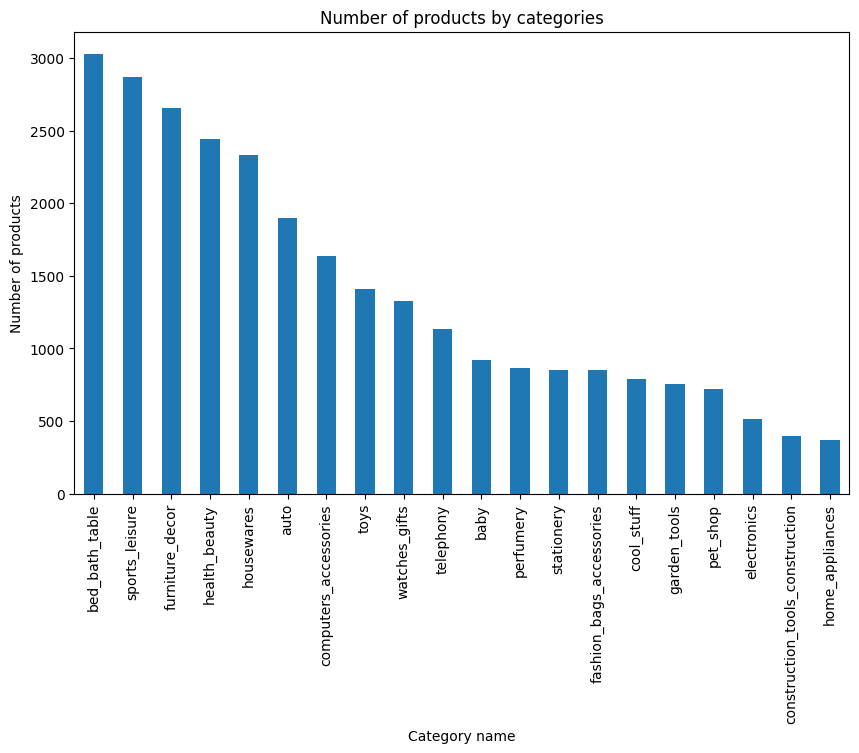

In [142]:
most_popular_categories.plot.bar(
    figsize=(10, 6),
    title="Number of products by categories",
    xlabel="Category name",
    ylabel="Number of products"
)

plt.show()

Insight:
- Bed & bath table has the largest product assortment, with 3,029 available items, followed by sports & leisure (2,867) and furniture & decor (2,657).
- The largest product assortments are concentrated in household and lifestyle categories, particularly bed & bath, furniture & decor, housewares, sports & leisure, and health & beauty.
- Health & beauty has a relatively large assortment, with 2,444 available items, placing it fourth among the categories shown.
- There is a substantial difference in product availability across categories: Bed & bath table has more than 8 times as many available items as home appliances (370).
- Several categories have relatively limited product variety, including construction tools & construction (400), home appliances (370), and electronics (517).
- Overall, the marketplace's product catalog is heavily focused on household, lifestyle, and everyday consumer categories, while some specialized categories have much smaller assortments.

### 3.4.3 Which categories generate the most revenue? Which categories are ordered the most?

In [19]:
products_categories_items_merged = pd.merge(
    left=orders_items_dataset[["order_id", "order_item_id", "product_id", "price", "freight_value"]],
    right=products_category_translated_merged[["product_id", "product_category_name_english"]],
    how="left",
    on="product_id",
    indicator=True
)

In [20]:
products_categories_items_merged["total_revenue"] = (
    products_categories_items_merged["price"] + products_categories_items_merged["freight_value"]
)

In [21]:
products_categories_summary = products_categories_items_merged.groupby(by="product_category_name_english").agg(
    total_revenue_per_category=("total_revenue", "sum"),
    total_orders_by_category=("order_id", "count")
).sort_values(by='total_orders_by_category', ascending=False).head(15)

In [22]:
products_categories_summary["total_revenue_per_category"].sort_values(ascending=False).head(15)

product_category_name_english
health_beauty            1441248.07
watches_gifts            1305541.61
bed_bath_table           1241681.72
sports_leisure           1156656.48
computers_accessories    1059272.40
furniture_decor           902511.79
housewares                778397.77
cool_stuff                719329.95
auto                      685384.32
garden_tools              584219.21
toys                      561372.55
baby                      480118.00
perfumery                 453338.71
telephony                 394883.32
electronics               206825.06
Name: total_revenue_per_category, dtype: float64

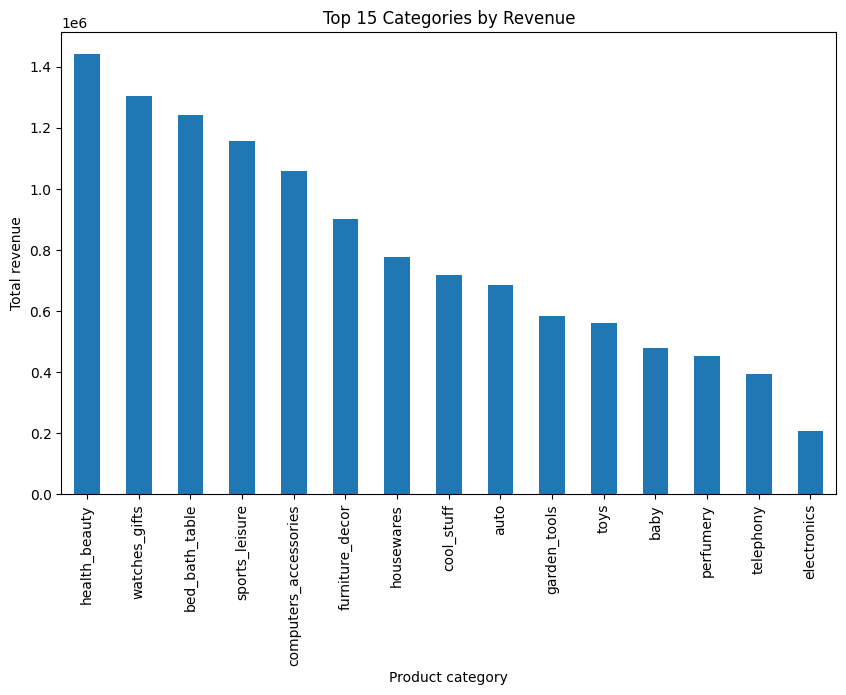

In [145]:
products_categories_summary["total_revenue_per_category"].sort_values(ascending=False).head(15).plot.bar(
    figsize=(10, 6),
    title="Top 15 Categories by Revenue",
    xlabel="Product category",
    ylabel="Total revenue"
)
plt.show()

Insight:
- Health & beauty generates the highest revenue, at approximately $1.44 million, making it the strongest-performing category among those shown.
- Watches & gifts is the second-highest revenue category, generating approximately $1.31 million, followed by bed & bath table ($1.24M) and sports & leisure ($1.16M).
- Computers & accessories is another strong revenue generator, producing approximately $1.06 million, placing it among the five highest-revenue categories.
- The lower-revenue categories show a substantial gap: Electronics generates approximately $207K, considerably below the leading categories despite being a relatively established product category.
- Overall, health & beauty, watches & gifts, bed & bath table, sports & leisure, and computers & accessories are the strongest revenue-generating categories in this analysis, each exceeding $1 million in total revenue.

In [24]:
products_categories_summary["total_orders_by_category"].sort_values(ascending=False).head(15)

product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
toys                      4117
cool_stuff                3796
perfumery                 3419
baby                      3065
electronics               2767
Name: total_orders_by_category, dtype: int64

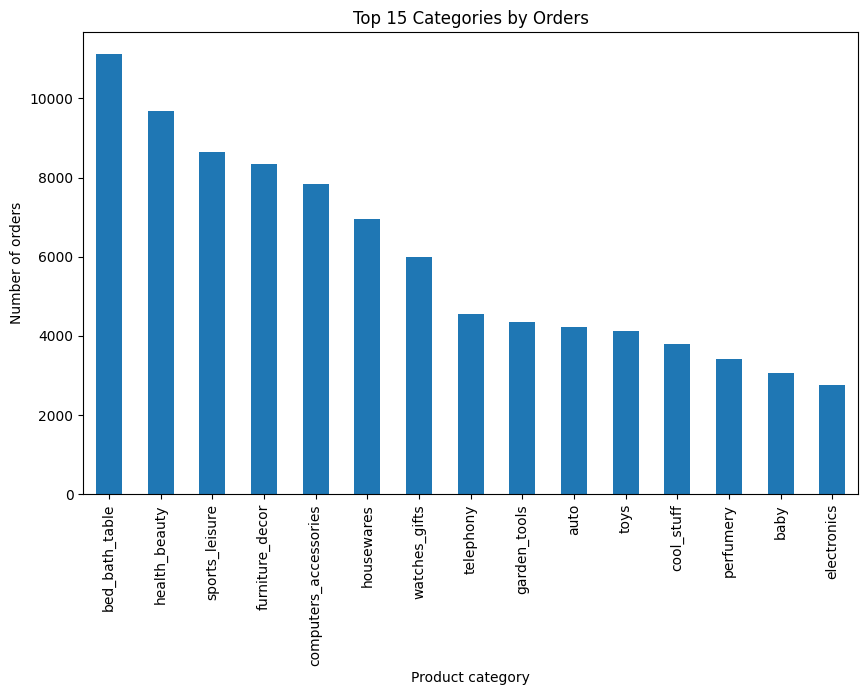

In [157]:
products_categories_summary["total_orders_by_category"].sort_values(ascending=False).head(15).plot.bar(
    figsize=(10, 6),
    title="Top 15 Categories by Orders",
    xlabel="Product category",
    ylabel="Number of orders"
)

plt.show()

Insight:
- Bed & bath table is the most frequently ordered category, with 11,115 orders, followed by health & beauty (9,670) and sports & leisure (8,641).
- The top five categories dominate order volume: Bed & bath table, health & beauty, sports & leisure, furniture & decor, and computers & accessories are the five most-ordered categories.
- Housewares also shows strong demand, with 6,964 orders, placing it sixth among the categories shown.
- Watches & gifts generates relatively fewer orders (5,991) despite being the second-highest revenue category in your previous analysis. This suggests that its orders may have a relatively higher value compared with categories such as bed & bath table.
- Electronics has the lowest order volume among these categories, with 2,767 orders, and it also had the lowest revenue among these categories in your previous analysis.
- Overall, order volume is concentrated in household, health & beauty, sports, and lifestyle categories, with bed & bath table standing out as the strongest category by number of orders.

## 3.5 Orders Analysis

### 3.5.1 How many orders?

In [26]:
#How many orders?
number_of_orders = orders_dataset["order_id"].nunique()
display(Markdown(f"Total number of unique orders: **{number_of_orders}**"))

Total number of unique orders: **99441**

### 3.5.2 What proportion of orders are delivered?

In [27]:
#What proportion of orders are delivered?
def orders_status_percentage(dataset, order_status):
    orders_with_status = dataset[dataset["order_status"] == order_status]
    percentage_of_orders = round((len(orders_with_status) / len(dataset)) * 100, 3)
    return Markdown(f"Percentage of **{order_status}** orders is **{percentage_of_orders}**%")

delivered_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="delivered"))
#What proportion of orders are cancelled?
canceled_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="canceled"))
unavailable_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="unavailable"))

Percentage of **delivered** orders is **97.02**%

Percentage of **canceled** orders is **0.629**%

Percentage of **unavailable** orders is **0.612**%

Insight:
- The vast majority of orders were successfully delivered: Approximately 97.02% of orders reached customers, indicating a highly reliable fulfillment process.
- Order failure rates are very low: Only 0.629% of orders were canceled and 0.612% were marked as unavailable, suggesting that issues related to order completion are relatively uncommon.
- The low cancellation rate indicates strong order commitment: Most customers who placed orders successfully completed the purchase process, with only a small fraction being canceled before completion.
- Product availability appears to be well managed: The unavailable order rate of 0.612% is very low, suggesting that inventory-related issues rarely prevented successful order fulfillment.
- Overall, the marketplace demonstrates strong operational performance, with a delivery success rate above 97% and minimal disruptions caused by cancellations or unavailable products.
- Potential area for further analysis: Although unsuccessful orders represent a small percentage, investigating the reasons behind cancellations and unavailable products could help identify opportunities to further improve customer experience.

## 3.6 Reviews Analysis

### 3.6.1 How many reviews?

In [28]:
repeated_reviews = reviews_dataset[reviews_dataset["review_id"].duplicated()].sort_values(by="review_id")
display(Markdown(f"Some reviews (**{len(repeated_reviews)}**) were found to be duplicated in all the columns except the order_id, which could suggest data anomaly."))

Some reviews (**814**) were found to be duplicated in all the columns except the order_id, which could suggest data anomaly.

These reviews represent a relatively small amount, so it was decied to remove them from future analysis

In [29]:
number_of_reviews = reviews_dataset["review_id"].nunique()
display(Markdown(f"Total number of reviews (unique): **{number_of_reviews}**"))

Total number of reviews (unique): **98410**

Insight:
- Repeated review IDs: **814** repeated review_id records were identified. Investigation showed that the repeated records contain identical review information but can be associated with different orders from the same customer. For review-level analysis, duplicate review_id records were therefore reduced to one record per review.
- Number of unique reviews: **98410**

### 3.6.2 What is the average review score? How are ratings distributed? What causes poor reviews? Do late deliveries lead to lower ratings?

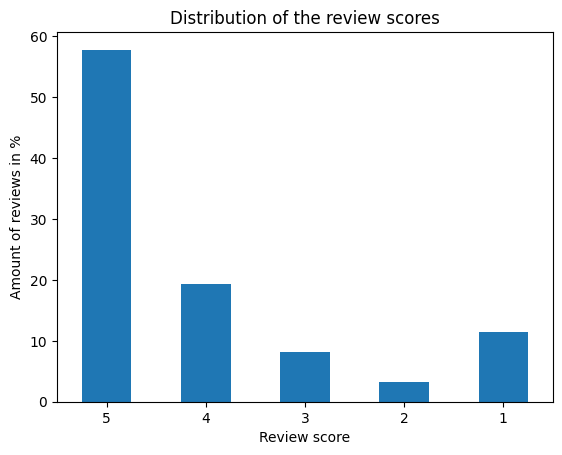

In [155]:
#What is the average review score?
average_review_score = reviews_dataset["review_score"].mean()

#How are ratings distributed?
reviews_distribution = reviews_dataset["review_score"].value_counts(normalize=True).sort_index(ascending=False) * 100

reviews_distribution.plot(kind="bar")
plt.xlabel("Review score")
plt.ylabel("Amount of reviews in %")
plt.title("Distribution of the review scores")
plt.xticks(rotation=0)
plt.show()

### 3.6.3 What cause poor reviews - NLP analysis

In [31]:
#What causes poor reviews?
one_point_reviews = reviews_dataset[reviews_dataset["review_score"] == 1]
one_point_reviews_message = one_point_reviews[one_point_reviews["review_comment_message"].notna()]


In [32]:
merged_one_star_review = pd.merge(
    left=one_point_reviews_message,
    right=orders_dataset,
    on="order_id",
    how="left",
    indicator=True
)

In [33]:
merged_one_star_review_with_delivery_date = (
    merged_one_star_review[merged_one_star_review["order_delivered_customer_date"].notna()]
)

In [ ]:
bigram_df = apply_nlp(dataset=merged_one_star_review_with_delivery_date, column_name="review_comment_message")

In [35]:
bigram_df.head(30)

,bigram,count,translated_bigrams
74,prazo entrega dia,27,delivery deadline day
39,entrar contato comigo,17,get in touch with me
69,passar prazo entrega,17,pass delivery deadline
87,recebi nota fiscal,16,I received an invoice
61,ninguém entrar contato,15,no one contact
42,entrar contato loja,14,contact store
41,entrar contato lannister,14,get in touch lannister
31,cumprir prazo entrega,14,meet delivery deadline
94,tentar entrar contato,14,try to get in touch
19,comprei recebi outro,14,I bought another one


Insight:
- Delivery delays are one of the main sources of customer complaints: Several frequent phrases relate to delivery deadlines, such as "delivery deadline day", "pass delivery deadline", and "meet delivery deadline", suggesting that customers frequently mention whether orders arrived within the expected timeframe.
- Customers often experienced problems when trying to contact sellers: Phrases such as "get in touch with me", "contact store", "no one contact", "try to get in touch", and "received no response" appear frequently, indicating that lack of communication and difficulty reaching sellers are important pain points.
- Invoice-related issues are common among customer complaints: Multiple frequent bigrams mention invoices, including "received an invoice", "issue invoice", "invoice appear", and "deliver invoice", suggesting that some customers experienced problems receiving or accessing their invoices.
- Product issues also appear in customer feedback: Phrases like "missing piece", "come color err", and "bought another one" suggest complaints related to missing components, incorrect product variations, or receiving products different from expectations.
- Slow delivery is a recurring dissatisfaction factor: The appearance of phrases such as "very slow delivery" and "delivery today" indicates that delivery speed and meeting promised dates strongly influence customer experiences.
- Overall, customer complaints appear to be concentrated around three main themes:
- Delivery performance — delays and missed deadlines
- Seller communication — difficulty receiving responses or support
- Order accuracy and documentation — missing items, incorrect products, and invoice issues
These results suggest that improving delivery reliability and customer-seller communication could have the biggest impact on customer satisfaction.

## 3.7 Platform Growth

### 3.7.1 Is the platform growing?

,Year,Orders,Growth (%)
0,2016,329,NaN
1,2017,45101,13608.51
2,2018,54011,19.76


,Month,Sales 2016,Sales 2017,Sales 2018
0,January,0,800,7269
1,February,0,1780,6728
2,March,0,2682,7211
3,April,0,2404,6939
4,May,0,3700,6873
5,June,0,3245,6167
6,July,0,4026,6292
7,August,0,4331,6512
8,September,4,4285,16
9,October,324,4631,4


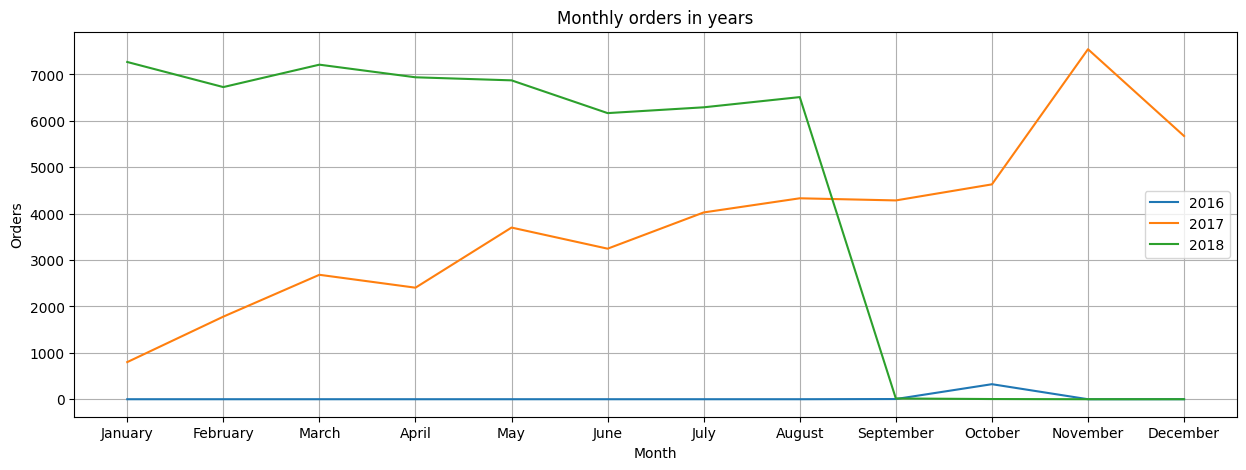

In [ ]:
#Is the platform growing?
#Are orders increasing or decreasing?
orders_purchased_2016 = orders_dataset["order_purchase_timestamp"].dt.year == 2016
orders_purchased_2017 = orders_dataset["order_purchase_timestamp"].dt.year == 2017
orders_purchased_2018 = orders_dataset["order_purchase_timestamp"].dt.year == 2018


yearly_sales = pd.DataFrame(
    {
        "Year": [2016, 2017, 2018],
        "Orders": [
          orders_purchased_2016.sum(),
          orders_purchased_2017.sum(),
          orders_purchased_2018.sum()  
        ]
    }
)

yearly_sales["Growth (%)"] = round(yearly_sales["Orders"].pct_change() * 100, 2)


display(yearly_sales) 

#Are there seasonal patterns?
#Which months are strongest?
def calculate_monthly_sale(dataset, year):
    monthly_sales = {}
    year_sales = dataset[dataset["order_purchase_timestamp"].dt.year == year]
    for month in range(1, 13):
        monthly_sales[month] = (year_sales["order_purchase_timestamp"].dt.month == month).sum()
    return monthly_sales

monthly_sales_2016 = calculate_monthly_sale(dataset=orders_dataset, year=2016)
monthly_sales_2017 = calculate_monthly_sale(dataset=orders_dataset, year=2017)
monthly_sales_2018 = calculate_monthly_sale(dataset=orders_dataset, year=2018)

pd_monthly_sales = pd.DataFrame(
    {
    "Month": ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"],
    "Sales 2016": monthly_sales_2016.values(),
    "Sales 2017": monthly_sales_2017.values(),
    "Sales 2018": monthly_sales_2018.values()
    }
)

display(pd_monthly_sales)

plt.figure(figsize=(15, 5))

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2016"],
    label = 2016
)

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2017"],
    label = 2017
)

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2018"],
    label = 2018
)

plt.title("Monthly orders in years")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.legend()
plt.grid()

plt.show()



Insight:
- Strong growth from 2016 to 2017: Orders increased from 329 to 45,101, representing approximately 13,609% growth. However, this percentage is heavily influenced by the very low 2016 baseline.
- Continued growth in 2018: Orders increased from 45,101 in 2017 to 54,011 in 2018, representing 19.76% growth.
- 2017 showed a general upward trend: Monthly orders increased throughout most of the year, from 800 in January to 4,631 in October.
- November 2017 was the strongest month: Orders peaked at 7,544, followed by 5,673 in December.
- 2018 started at a consistently high level: From January through August, monthly orders remained between approximately 6,500 and 7,300, suggesting a much higher and more stable order volume than at the beginning of 2017.
- Potential data-quality issue in late 2018: Orders dropped dramatically from 6,512 in August to only 16 in September, followed by 4 in October and 0 in November and December.
- The late-2018 decline should be investigated: This unusual pattern may indicate a data-coverage or completeness issue, so it should not automatically be interpreted as a genuine collapse in demand.

### 3.7.2 Revenue Analysis

In [37]:
orders_items_status_merged = pd.merge(
    left=orders_items_dataset[["order_id", "order_item_id", "price", "freight_value"]],
    right=orders_dataset[["order_id", "order_status", "order_delivered_customer_date"]],
    how="left",
    on="order_id",
    indicator=True
)

In [38]:
orders_items_status_merged["total_price"] = orders_items_status_merged["price"] + orders_items_status_merged["freight_value"]

In [39]:
revenues_by_order_status = orders_items_status_merged.groupby("order_status").agg(
    revenue_by_status=("total_price", "sum")
)

total_revenue = revenues_by_order_status.loc["delivered", "revenue_by_status"]

In [40]:
display(Markdown(f"The total revenue is: **${total_revenue:,.2f}**"))

The total revenue is: **$15,419,773.75**

Insight:
- Delivered orders generated approximately $15.42 million in realized revenue, representing the actual revenue earned from successfully completed purchases.
- Revenue analysis should focus on delivered orders only, as canceled, unavailable, and incomplete orders do not represent completed sales.
- The high proportion of delivered orders (97.02%) combined with the realized revenue value indicates strong operational performance, with most placed orders successfully converting into completed transactions.
- The difference between total order value and delivered revenue can be used to evaluate revenue loss from unsuccessful orders, such as cancellations or unavailable products.
- Overall, the marketplace generated substantial revenue from completed orders, suggesting effective fulfillment and a low rate of failed transactions.

## 3.8 Delivery Analysis

### 3.8.1 How long does delivery take? Are deliveries usually on time? Which regions have slower delivery? How often are deliveries late?


Analyze Delivery Performance

In [41]:
#How long does delivery take?
#We will only consider the delivered status orders
delivered_orders = orders_dataset[orders_dataset["order_status"] == "delivered"]
delivered_orders["order_status"].value_counts()
display(Markdown(f"Percentage of delivered orders is: **{round((len(delivered_orders) / len(orders_dataset)) * 100, 2)}**%"))


Percentage of delivered orders is: **97.02**%

Insight:
- The marketplace demonstrates strong order fulfillment performance, with 97.02% of orders successfully delivered to customers.
- The high delivery success rate indicates that the majority of purchases are completed without operational issues, suggesting effective logistics and seller fulfillment processes.

In [42]:
delivered_orders["total_delivery_time"] = delivered_orders["order_delivered_customer_date"] - delivered_orders["order_purchase_timestamp"]
delivered_orders["total_delivery_time"].dt.total_seconds() / 86400

0         8.436574
1        13.782037
2         9.394213
3        13.208750
4         2.873877
           ...    
99436     8.218009
99437    22.193727
99438    24.859421
99439    17.086424
99440     7.674306
Name: total_delivery_time, Length: 96478, dtype: float64

In [43]:
average_delivery_time = delivered_orders["total_delivery_time"].mean().total_seconds() / 86400

In [44]:
display(Markdown(f"Average delivery time: **{round(average_delivery_time, 2)}** days"))

Average delivery time: **12.56** days

Insight:
- The average delivery time was 12.56 days, meaning that, on average, customers waited roughly 12 and a half days from purchase to receiving their order.

In [45]:
delivered_orders["delivery_days"] = (
    delivered_orders["total_delivery_time"]
    .dt.total_seconds()
    / 86400
)

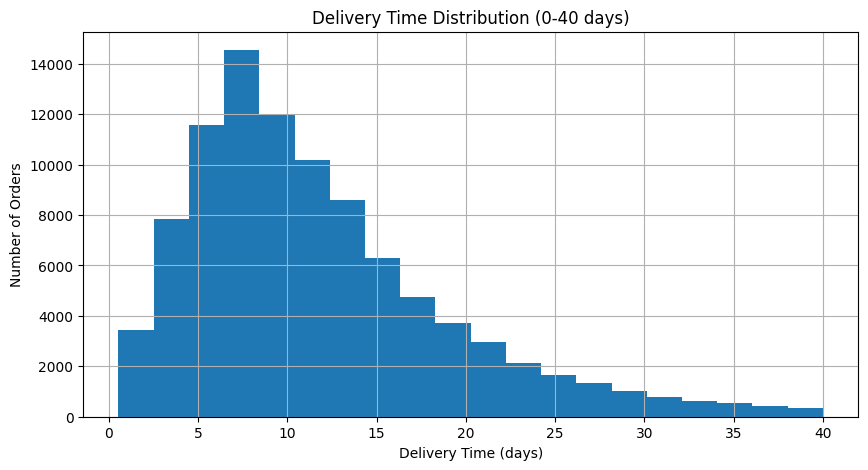

In [46]:
delivered_orders[delivered_orders["delivery_days"] <= 40]["delivery_days"].hist(bins=20, figsize=(10,5))


plt.xlabel("Delivery Time (days)")
plt.ylabel("Number of Orders")
plt.title("Delivery Time Distribution (0-40 days)")
plt.show()

Insight:
- Delivery times are concentrated around 5–10 days, with the highest number of orders delivered at approximately 7–8 days.
- The distribution is right-skewed, meaning most orders are delivered relatively quickly, while a smaller number of orders take substantially longer.
- Most deliveries occur within roughly 15 days, after which the number of orders decreases steadily.
- There is a long tail extending to 40 days, indicating that a smaller group of customers experienced significantly longer delivery times.
- The average delivery time of 12.56 days is higher than the most common delivery time, which is consistent with the right-skewed distribution: the relatively late deliveries pull the average upward.
- Overall, the typical delivery appears to be considerably faster than the 12.56-day average, but a minority of delayed orders increases the overall average. This suggests that examining the median and late-delivery percentage alongside the mean would give a better picture of the typical customer experience.

In [47]:
#Are deliveries usually on time?
#How often are deliveries late?
late_delivery = (delivered_orders["order_delivered_customer_date"] > delivered_orders["order_estimated_delivery_date"])
late_orders = (delivered_orders[late_delivery])

#Calculate the percentage of late orders
late_delivery_percentage = round(late_delivery.mean() * 100, 2)
display(Markdown(f"The percentage of late delivered orders is: **{late_delivery_percentage}**%"))

#Calculate the average amount of time of order being late
late_delivery_time = (late_orders["order_delivered_customer_date"] - late_orders["order_estimated_delivery_date"])
average_late_delivery_time = late_delivery_time.dt.total_seconds().mean() / 86400
display(Markdown(f"Average late delivery time is: **{round(average_late_delivery_time, 2)}** days"))

The percentage of late delivered orders is: **8.11**%

Average late delivery time is: **9.55** days

Insight:
- 8.11% of delivered orders were late, meaning that approximately 1 in every 12 delivered orders missed the expected delivery date.
- The average late delivery was 9.55 days, indicating that when delays occurred, they were relatively substantial rather than just minor deviations from the expected delivery date.
- While the overall delivery success rate is high (97.02%), the 8.11% late-delivery rate highlights a noticeable logistics issue that could negatively affect customer satisfaction.
- Combined with the delivery-time distribution, this suggests that most orders are delivered within a reasonable timeframe, but a smaller group experiences significant delays.
- Overall, improving the frequency and duration of late deliveries could be an important area for improving the customer experience.

In [ ]:
#Which regions have slower delivery?
orders_customers_merged = pd.merge(
    left=delivered_orders,
    right=customers_dataset[["customer_id", "customer_zip_code_prefix", "customer_city", "customer_state"]],
    on="customer_id",
    how="left",
    indicator=True
)

orders_customers_merged["total_delivery_time"] = orders_customers_merged["order_delivered_customer_date"] - orders_customers_merged["order_purchase_timestamp"]

state_delivery = orders_customers_merged.groupby("customer_state")["total_delivery_time"].mean().dt.days.sort_values(ascending=False)
city_delivery = orders_customers_merged.groupby("customer_city")["total_delivery_time"].mean().dt.days.sort_values(ascending=False)

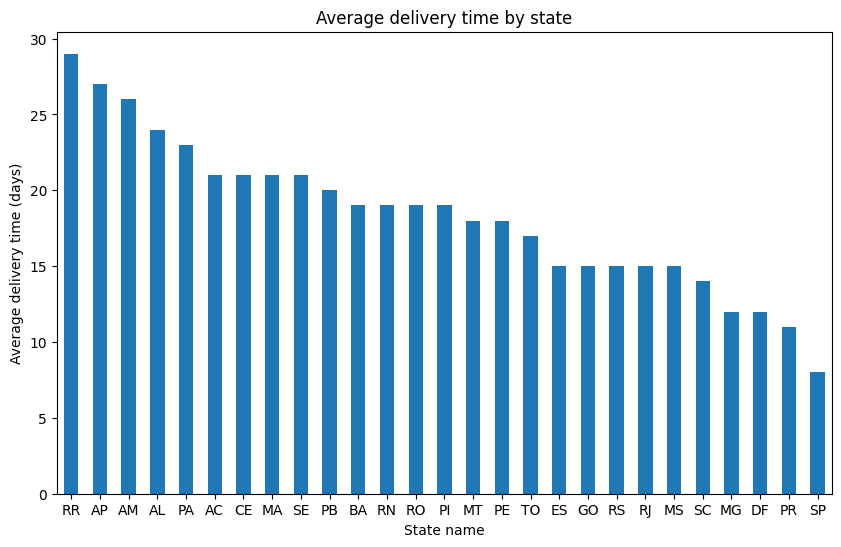

In [161]:
state_delivery.plot.bar(
    figsize=(10, 6),
    title="Average delivery time by state",
    xlabel="State name",
    ylabel="Average delivery time (days)"
)

plt.xticks(rotation=0)
plt.show()

Insight:
- Delivery times vary significantly across Brazilian states, with average delivery times ranging from 8 days in São Paulo (SP) to 29 days in Roraima (RR), showing a difference of more than three weeks between the fastest and slowest regions.
- Northern states experience the longest average delivery times, with states such as Roraima (29 days), Amapá (27 days), Amazonas (26 days), and Pará (23 days) among the slowest. This suggests that geographic distance, logistics infrastructure, and accessibility may strongly influence delivery performance.
- Southeastern and southern states generally receive orders faster, with São Paulo (8 days), Paraná (11 days), Minas Gerais (12 days), and Santa Catarina (14 days) having some of the shortest delivery times. This may be related to higher seller concentration and better-developed logistics networks in these regions.
- São Paulo stands out as the fastest-delivery state, likely due to being the largest commercial hub in the marketplace, with a high concentration of sellers and distribution infrastructure.
- The large regional differences indicate that delivery performance is not uniform across the country, and customers in more remote states face significantly longer waiting times.
- Improving logistics coverage and delivery infrastructure in northern regions could reduce delivery inequalities and improve customer satisfaction in those areas.

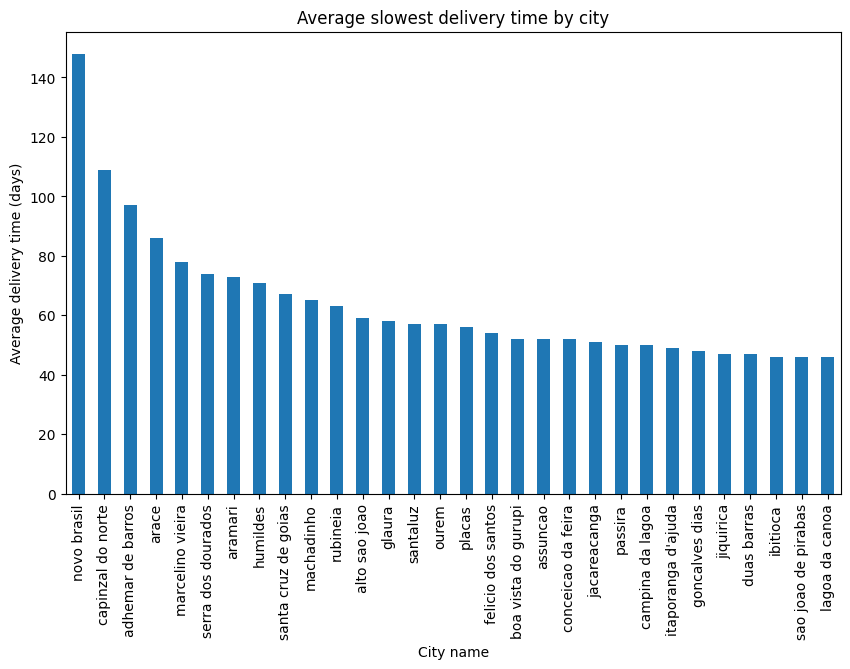

In [164]:
city_delivery.head(30).plot.bar(
    figsize=(10,6),
    title="Average slowest delivery time by city",
    xlabel="City name",
    ylabel="Average delivery time (days)"
)
plt.show()

Insight:
- Delivery performance varies significantly by city, with the slowest locations experiencing extremely long average delivery times compared with major urban centers. The slowest city, Novo Brasil, has an average delivery time of 148 days, indicating a major delivery bottleneck.
- The cities with the longest delivery times are mostly smaller and less populated locations, such as Novo Brasil, Capinzal do Norte, Arace, - Marcelino Vieira, and Serra dos Dourados, suggesting that geographic remoteness and limited logistics infrastructure may contribute to longer delivery periods.
- Remote cities appear to face disproportionate delivery delays, likely due to factors such as:
    longer distances from sellers and distribution centers,
    fewer transportation options,
    lower logistics coverage compared with large metropolitan areas.
- The extreme values observed in some cities suggest that average delivery time may be affected by outliers, such as individual orders with unusually long delays. These cities should be investigated further to determine whether the delays represent a consistent pattern or isolated cases.
- Compared with state-level results, city-level analysis reveals greater variation in delivery performance, highlighting that logistics challenges are often concentrated in specific locations rather than affecting entire regions uniformly.
- Overall, the results suggest that improving last-mile logistics in smaller and remote cities could significantly improve delivery reliability and customer satisfaction

## 3.9 Payment Analysis

### 3.9.1 Which payment methods are most common? Are installments heavily used?

In [51]:
order_payments_count = order_payments_dataset.groupby(by="payment_type")
payments_types_count = order_payments_count.size().sort_values(ascending=False)[:4]

In [52]:
payments_types_count

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
dtype: int64

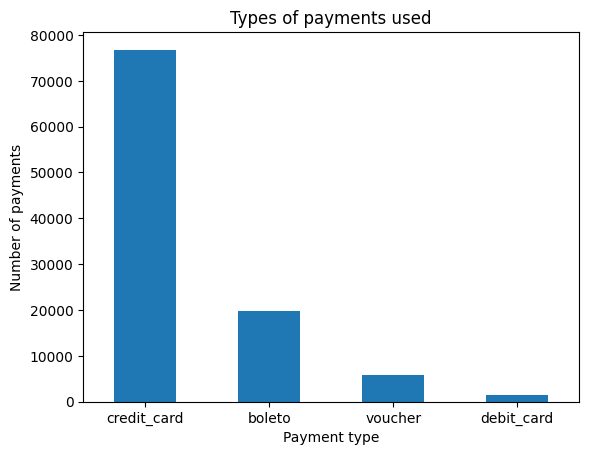

In [167]:
payments_types_count.plot.bar(
    title="Types of payments used",
    xlabel="Payment type",
    ylabel="Number of payments"
)

plt.xticks(rotation=0)
plt.show()

Insight:
- Credit cards are by far the most common payment method, accounting for 76,795 payments, indicating a strong preference for card-based transactions.
- Boleto is the second most used payment method, with 19,784 payments, showing that it remains a significant alternative to credit cards.
- Voucher payments account for 5,775 transactions, while debit cards are used much less frequently, with only 1,529 payments.
- Overall, payment activity is heavily concentrated in credit cards and boleto, while debit cards and vouchers represent a relatively small share of transactions.
- This suggests that supporting and optimizing credit-card and boleto payment options is particularly important for the marketplace, as these methods account for the vast majority of payments.

In [54]:
#Are installments heavily used?
payment_installments = order_payments_dataset.groupby(by="payment_type")["payment_installments"].max()
#Payment installments are only present in the credit_card type payment
display(payment_installments)

payment_type
boleto          1
credit_card    24
debit_card      1
not_defined     1
voucher         1
Name: payment_installments, dtype: int64

In [55]:
credit_card_payments = order_payments_dataset[order_payments_dataset["payment_type"] == "credit_card"]
credit_card_payments.head()

payment_installments_groups = credit_card_payments.groupby("payment_installments")["order_id"].count().sort_index().loc[1:10]
payment_installments_groups

payment_installments
1     25455
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
Name: order_id, dtype: int64

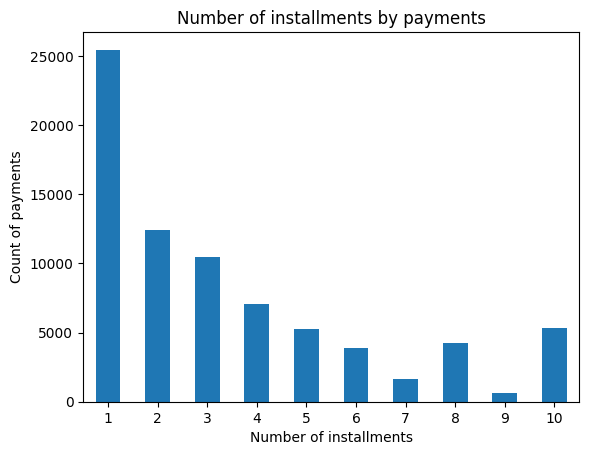

In [169]:
payment_installments_groups.plot.bar(
    title="Number of installments by payments",
)

plt.xlabel("Number of installments")
plt.ylabel("Count of payments")
plt.xticks(rotation=0)

plt.show()

In [57]:
credit_card_installments_percentages = (
    credit_card_payments["payment_installments"]
    .value_counts(normalize=True)
    .sort_index()
    .loc[1:10]
    .mul(100)
)

credit_card_installments_percentages

payment_installments
1     33.146689
2     16.163813
3     13.621981
4      9.242789
5      6.822059
6      5.104499
7      2.117325
8      5.557653
9      0.838596
10     6.937952
Name: proportion, dtype: float64

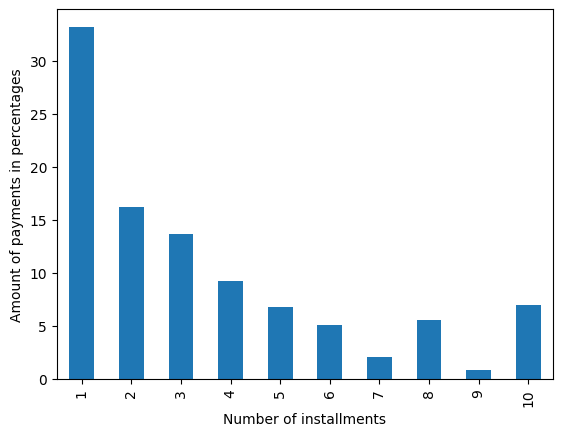

In [58]:
credit_card_installments_percentages.plot.bar()

plt.xlabel("Number of installments")
plt.ylabel("Amount of payments in percentages")

plt.show()

Insight:
- Single-payment purchases are the most common, with 1 installment clearly accounting for the largest number of payments.
- There is a general decline in payment frequency as the number of installments increases, particularly from 2 through 7 installments.
- Higher installment plans are still used, especially 8 and 10 installments, suggesting that some customers prefer spreading larger purchases over a longer period.
- 10 installments stand out as an exception to the declining pattern, with noticeably more payments than 7 or 9 installments. This may indicate that 10 installments is a commonly selected financing option, rather than installment usage simply decreasing continuously with the number of payments.
- Overall, the distribution suggests that customers tend to prefer paying in full or using a relatively small number of installments, while longer installment plans are used by a smaller but meaningful portion of customers.
- The pattern is consistent with installment payments being used as a financing tool for purchases where customers want to spread the cost over time.

## 3.10 Connect Everything

### 3.10.1 Delivery vs Reviews - Do delayed deliveries receive worse ratings?

In [ ]:
merged_delivered_orders_reviews = pd.merge(
    left=delivered_orders,
    right=reviews_dataset,
    on="order_id",
    how="left",
    indicator=True
)

In [ ]:
#Drop the orders without a review
merged_delivered_orders_reviews = merged_delivered_orders_reviews.dropna(subset=["review_score"])

In [ ]:
#Add column which specifies if the delivery was late
merged_delivered_orders_reviews["late_delivery?"] = (
    merged_delivered_orders_reviews["order_delivered_customer_date"] > merged_delivered_orders_reviews["order_estimated_delivery_date"]
)

In [85]:
merged_delivered_orders_reviews_grouped = (
    merged_delivered_orders_reviews.groupby("late_delivery?")
)

late_delivery = merged_delivered_orders_reviews_grouped.get_group(True)
on_time_delivery = merged_delivered_orders_reviews_grouped.get_group(False)

print("The score distribution for the late delivery orders")
display(late_delivery["review_score"].value_counts())
print("The score distribution for the orders in time")
display(on_time_delivery["review_score"].value_counts())

The score distribution for the late delivery orders


review_score
1.0    3554
5.0    1711
4.0     954
3.0     875
2.0     606
Name: count, dtype: int64

The score distribution for the orders in time


review_score
5.0    55355
4.0    18033
3.0     7086
1.0     5852
2.0     2335
Name: count, dtype: int64

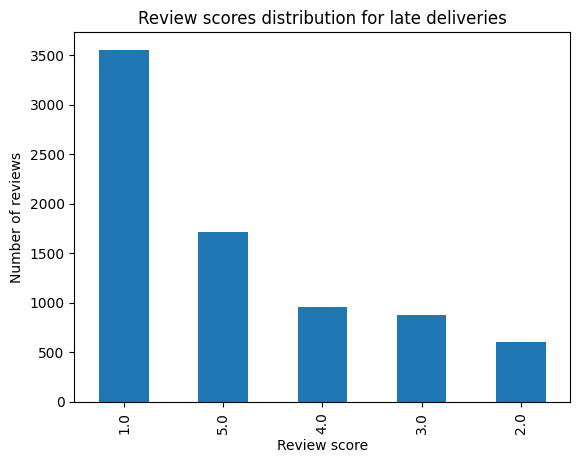

In [90]:
late_delivery["review_score"].value_counts().plot.bar(
    title="Review scores distribution for late deliveries",
    xlabel="Review score",
    ylabel="Number of reviews"
)
plt.show()

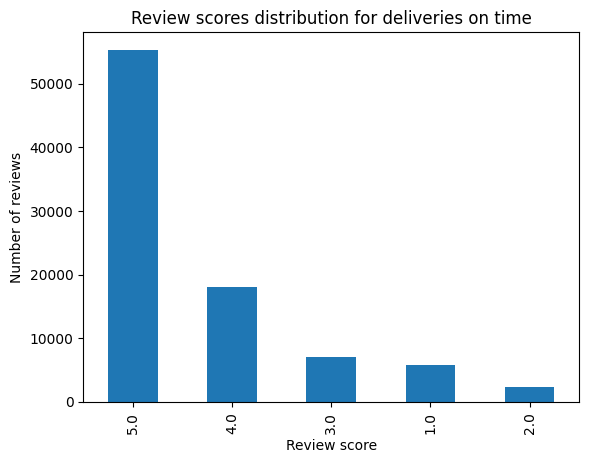

In [91]:
on_time_delivery["review_score"].value_counts().plot.bar(
    title="Review scores distribution for deliveries on time",
    xlabel="Review score",
    ylabel="Number of reviews"
)
plt.show()

Insight:
- Late deliveries are strongly associated with lower review scores. A score of 1 is the most common rating among late orders (3,554 reviews), while 5-star ratings are less frequent (1,711).
- In contrast, on-time orders are dominated by positive reviews, with 5-star ratings being the most common (55,355 reviews), followed by 4-star ratings (18,033).
- 1-star reviews account for a much larger proportion of late orders than on-time orders, suggesting that delivery delays have a substantial negative impact on customer satisfaction.
- Although some late orders still receive high ratings, the distribution indicates that customers are considerably more likely to leave poor reviews when their orders arrive late.
- Overall, delivery performance appears to be an important driver of customer satisfaction: late delivery is associated with a shift toward lower review scores, while on-time delivery is associated with predominantly positive ratings.

### 3.10.2 Are some categories rated more poorly?

In [99]:
merged_product_category_orders = pd.merge(
    left=orders_items_dataset[["order_id", "order_item_id", "product_id"]],
    right=products_dataset[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    indicator=True
)

In [100]:
merged_product_category_orders_reviews = pd.merge(
    left=merged_product_category_orders[["order_id", "order_item_id", "product_id", "product_category_name"]],
    right=reviews_dataset[["order_id", "review_score", "review_comment_title", "review_comment_message"]],
    how="left",
    on="order_id",
    indicator=True
)

In [101]:
merged_product_category_orders_reviews = merged_product_category_orders_reviews.dropna(subset="review_score")
merged_product_category_orders_reviews = merged_product_category_orders_reviews.drop(columns=["_merge"])

In [103]:
merged_product_category_orders_reviews = pd.merge(
    left=merged_product_category_orders_reviews,
    right=category_translation_dataset,
    how="left",
    on="product_category_name",
    indicator=True
)

In [104]:
grouped_reviews_categories = merged_product_category_orders_reviews.groupby("product_category_name_english")["review_score"]

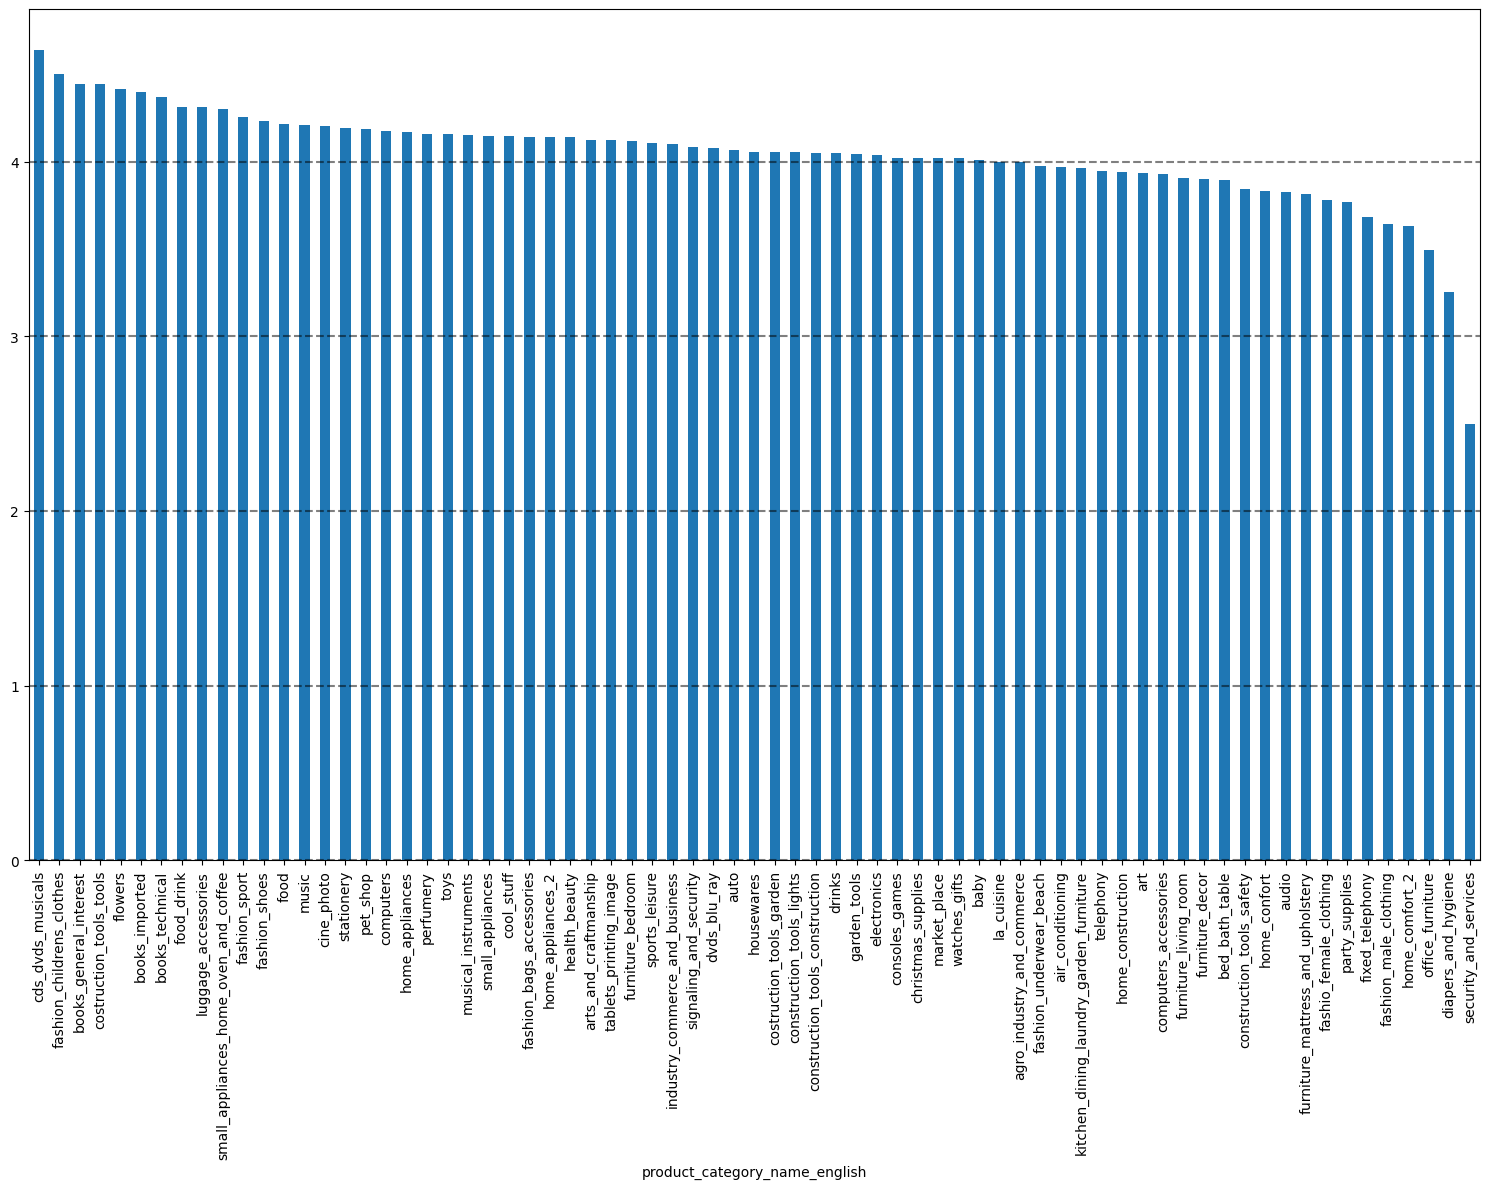

In [77]:
grouped_reviews_categories.mean().sort_values(ascending=False).plot.bar(figsize=(15, 12))

plt.grid(
    axis="y",
    color="black",
    linewidth=1.5,
    linestyle="--",
    alpha=0.5
)


plt.tight_layout()


plt.show()

In [110]:
grouped_products_orders = merged_product_category_orders_reviews.groupby("product_category_name_english")
grouped_products_orders.agg(
    number_of_orders=("order_id", "count"),
    average_review_score=("review_score", "mean")
).sort_values(by="average_review_score", ascending=False).head(20)

,number_of_orders,average_review_score
product_category_name_english,,
cds_dvds_musicals,14,4.642857
fashion_childrens_clothes,8,4.500000
books_general_interest,549,4.446266
costruction_tools_tools,99,4.444444
flowers,31,4.419355
books_imported,60,4.400000
books_technical,266,4.368421
food_drink,279,4.315412
luggage_accessories,1088,4.315257


Insight:
- Customer satisfaction varies considerably across product categories, with average review scores ranging from around 3.49 to 4.64.
Books, media, and some fashion categories receive some of the highest ratings. Books general interest (4.45 from 549 orders), books technical (4.37 from 266 orders), and luggage & accessories (4.32 from 1,088 orders) all show relatively strong customer satisfaction.
- Some high-rated categories also have substantial order volumes, making their results more meaningful. For example, stationery has 2,507 orders with an average score of 4.19, pet shop has 1,939 orders with 4.19, and perfumery has 3,421 orders with 4.16.
- Furniture and home-related categories tend to have lower review scores. Office furniture stands out with only 3.49 stars across 1,687 orders, while furniture decor (3.90 across 8,331 orders) and bed & bath table (3.90 across 11,137 orders) also have relatively lower ratings.
- The contrast is particularly interesting because some of the lower-rated categories have very high order volumes. Bed & bath table and furniture decor therefore represent potentially more significant customer-satisfaction concerns than categories with similarly low ratings but only a few orders.
- Technology-related categories show mixed results. Computers/accessories has a relatively moderate score of 3.93 across 7,849 orders, while computers itself has a stronger 4.18 across 200 orders. Telephony also has a moderate score of 3.95 across 4,517 orders.
- Small categories should be interpreted cautiously. For example, CDs/DVDs/musicals has the highest average score (4.64) but only 14 orders, while fashion children's clothes has 8 orders. These high averages may not represent the broader customer experience reliably.

### 3.10.3 Are expensive purchases reviewed differently?

In [ ]:
grouped_order_payments = order_payments_dataset.groupby("order_id")["payment_value"].sum().reset_index()

In [115]:
grouped_order_payments_review = pd.merge(
    left=grouped_order_payments,
    right=reviews_dataset,
    how="left",
    on="order_id",
    indicator=True
)

In [116]:
grouped_order_payments_review = grouped_order_payments_review.dropna(subset="review_score")

In [117]:
grouped_order_payments_review["payment_value"].describe()

grouped_order_payments_review["value_group"] = pd.qcut(
    grouped_order_payments_review["payment_value"],
    q=4,
    labels=[
        "Cheap",
        "Lower-Middle",
        "Upper-Middle",
        "Expensive"
    ]
)

In [119]:
grouped_order_payments_review_agg = (
    grouped_order_payments_review.groupby("value_group").agg(
        average_review_score=("review_score", "mean"),
        number_of_orders=("order_id", "count")
    )
)
grouped_order_payments_review_agg

,average_review_score,number_of_orders
value_group,,
Cheap,4.176575,24811
Lower-Middle,4.111812,24872
Upper-Middle,4.089616,24739
Expensive,3.967703,24801


Insight:
- There is a clear negative relationship between purchase value and review score. The average review score decreases consistently as the order value increases.
- Cheap purchases received the highest average rating at 4.18, while Expensive purchases received the lowest at 3.97.
- The difference between the cheapest and most expensive groups is about 0.21 points, suggesting that customers tend to rate higher-value purchases somewhat less favorably.
- The pattern is consistent across all four groups: 4.18 → 4.11 → 4.09 → 3.97, making the decline fairly systematic rather than being driven by one unusual group.
- Because each group contains approximately 24,700–24,900 orders, the comparison is well balanced and the differences are more meaningful than if some groups had very small sample sizes.

### 3.10.4 Does geography affect customer experience?

In [120]:
merged_geolocation_orders = pd.merge(
    left=delivered_orders[["customer_id", "order_status", "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]],
    right=customers_dataset[["customer_id", "customer_zip_code_prefix", "customer_city", "customer_state"]],
    on="customer_id",
    how="left",
    indicator=True
)

In [122]:
merged_geolocation_orders["delivery_time"] = (
    merged_geolocation_orders["order_delivered_customer_date"] - merged_geolocation_orders["order_purchase_timestamp"]
)

merged_geolocation_orders["late_delivery?"] = (
    merged_geolocation_orders["order_delivered_customer_date"] > merged_geolocation_orders["order_estimated_delivery_date"]
)

In [123]:
orders_time_by_location_grouped = (
    merged_geolocation_orders.groupby("customer_state").agg(
        average_delivery=("delivery_time", "mean"),
        later_orders=("late_delivery?", "sum")
    )
)

In [124]:
orders_time_by_location_grouped["average_delivery_days"] = (
    orders_time_by_location_grouped["average_delivery"]
    .dt.total_seconds() / (24 * 60 * 60)
)

In [ ]:
orders_time_by_location_grouped.sort_values("average_delivery_days")

,average_delivery,later_orders,average_delivery_days
customer_state,,,
SP,8 days 18:16:23.750061,2387,8.761386
PR,11 days 23:47:52.704448,246,11.991582
MG,12 days 00:12:28.711819,637,12.008666
DF,12 days 23:13:17.884615,147,12.967568
SC,14 days 22:54:53.240552,346,14.954783
RS,15 days 07:12:23.863023,382,15.300276
RJ,15 days 07:25:35.403643,1664,15.309438
GO,15 days 14:33:07.649463,160,15.606339
MS,15 days 14:50:22.763195,81,15.618319


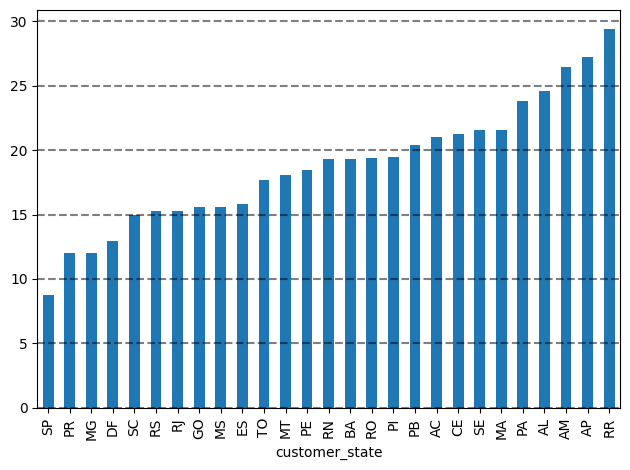

In [ ]:
orders_time_by_location_grouped.sort_values(
    "average_delivery_days",
    ascending=True
)["average_delivery_days"].plot.bar()

plt.grid(
    axis="y",
    color="black",
    linewidth=1.5,
    linestyle="--",
    alpha=0.5
    
)

plt.tight_layout()

plt.show()

Insight:
- Delivery performance varies substantially by customer state, with average delivery times ranging from 8.76 days in São Paulo (SP) to 29.39 days in Roraima (RR).
- São Paulo has by far the fastest average delivery time, at 8.76 days, and also has the highest number of late orders in the table (2,387). This is important because the large number of late orders is partly related to SP having a much larger customer/order volume.
- Northern states generally have the longest delivery times. RR (29.39 days), AP (27.19), AM (26.43), AL (24.54), and PA (23.77) are among the slowest states, showing a substantial geographic disparity in delivery performance.
- Southern and southeastern states generally have shorter delivery times, particularly SP (8.76), PR (11.99), MG (12.01), and SC (14.95).
- There is a clear geographical pattern: states with longer average delivery times tend to be farther from the main seller concentration, while states closer to major commercial and logistics centers tend to receive orders faster.
- The number of late orders should be interpreted alongside the average delivery time. For example, SP has 2,387 late orders, but this does not necessarily mean SP has worse delivery performance than RR, because SP has a much larger order volume.
- Some states have very small numbers of late orders, such as AC (3), AP (3), RR (5), and RO (7). Their high average delivery times are therefore useful as an indication of potentially slow logistics, but should be interpreted cautiously because of the small sample sizes.